# 01 — Inspection, Cleaning & Preprocessing

1. Raw inspection
2. Cleaning rules
3. Preprocessing pipeline (impute, scale, one-hot)
4. Transformed matrix preview


In [12]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted')

df = pd.read_csv(ROOT / 'data' / 'productivity_dataset.csv')
print('Shape:', df.shape)
df.head()


Shape: (30000, 19)


,age,gender,job_type,daily_social_media_time,social_platform_preference,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,30,Male,Finance,2.00,Telegram,32,8.00,6,8.00,5,8.00,1,3,True,True,1,0,20,6
1,24,Female,Health,2.00,Instagram,19,12.00,7,4.00,6,6.00,0,2,False,False,2,8,8,5
2,52,Female,Student,4.00,Telegram,80,5.00,5,7.00,3,8.00,2,3,True,False,1,0,13,8
3,58,Female,IT,2.00,TikTok,103,6.00,7,6.00,3,7.00,1,0,True,True,1,1,15,8
4,61,Female,Student,4.00,Twitter,114,6.00,6,4.00,5,8.00,3,2,False,False,1,5,14,6


## Column types


In [13]:
print(df.dtypes)
print('\nNumeric:', df.select_dtypes(include='number').columns.tolist())
print('Object:', df.select_dtypes(include='object').columns.tolist())
print('Bool:', df.select_dtypes(include='bool').columns.tolist())


age                                 int64
gender                                str
job_type                              str
daily_social_media_time           float64
social_platform_preference            str
number_of_notifications             int64
work_hours_per_day                float64
perceived_productivity_score        int64
actual_productivity_score         float64
stress_level                        int64
sleep_hours                       float64
screen_time_before_sleep            int64
breaks_during_work                  int64
uses_focus_apps                      bool
has_digital_wellbeing_enabled        bool
coffee_consumption_per_day          int64
days_feeling_burnout_per_month      int64
weekly_offline_hours                int64
job_satisfaction_score              int64
dtype: object

Numeric: ['age', 'daily_social_media_time', 'number_of_notifications', 'work_hours_per_day', 'perceived_productivity_score', 'actual_productivity_score', 'stress_level', 'sleep_hours', 's

C:\Users\ahmed\AppData\Local\Temp\ipykernel_1604\816884754.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print('Object:', df.select_dtypes(include='object').columns.tolist())


## Missing values


job_type                      624
social_platform_preference    612
daily_social_media_time       604
sleep_hours                   593
work_hours_per_day            577
actual_productivity_score      39
dtype: int64

Target missing: 39


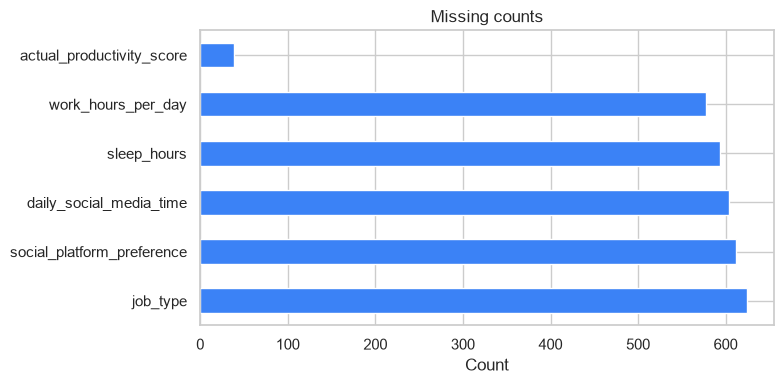

In [14]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print(miss)
print(f"\nTarget missing: {df['actual_productivity_score'].isna().sum()}")
miss.plot(kind='barh', figsize=(8, 4), color='#3b82f6')
plt.title('Missing counts')
plt.xlabel('Count')
plt.tight_layout()
plt.show()


## Numeric summary


In [15]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,30000.00,39.31,12.00,18.00,30.00,39.00,48.00,64.00
daily_social_media_time,29396.00,2.41,1.63,0.00,1.00,2.00,3.00,10.00
number_of_notifications,30000.00,66.56,35.98,10.00,40.00,63.00,88.00,199.00
work_hours_per_day,29423.00,7.83,1.90,2.00,6.00,8.00,9.00,12.00
perceived_productivity_score,30000.00,7.10,1.15,2.00,6.00,7.00,8.00,10.00
actual_productivity_score,29961.00,6.63,1.80,3.00,5.00,7.00,8.00,10.00
stress_level,30000.00,3.43,1.65,1.00,2.00,3.00,4.00,9.00
sleep_hours,29407.00,7.35,1.07,4.00,7.00,7.00,8.00,10.00
screen_time_before_sleep,30000.00,1.03,0.76,0.00,0.00,1.00,2.00,4.00
breaks_during_work,30000.00,3.12,1.42,0.00,2.00,3.00,4.00,7.00


## Categorical distributions (before fill)


In [16]:
for col in ['gender','job_type','social_platform_preference']:
    print(f'\n--- {col} ---')
    print(df[col].value_counts(dropna=False))



--- gender ---
gender
Male      14731
Female    14119
Other      1150
Name: count, dtype: int64

--- job_type ---
job_type
Student       6552
IT            5614
Health        4990
Finance       4362
Education     4074
Unemployed    3784
NaN            624
Name: count, dtype: int64

--- social_platform_preference ---
social_platform_preference
Instagram    8443
TikTok       7310
Facebook     5284
Telegram     4740
Twitter      3611
NaN           612
Name: count, dtype: int64


## Target distribution


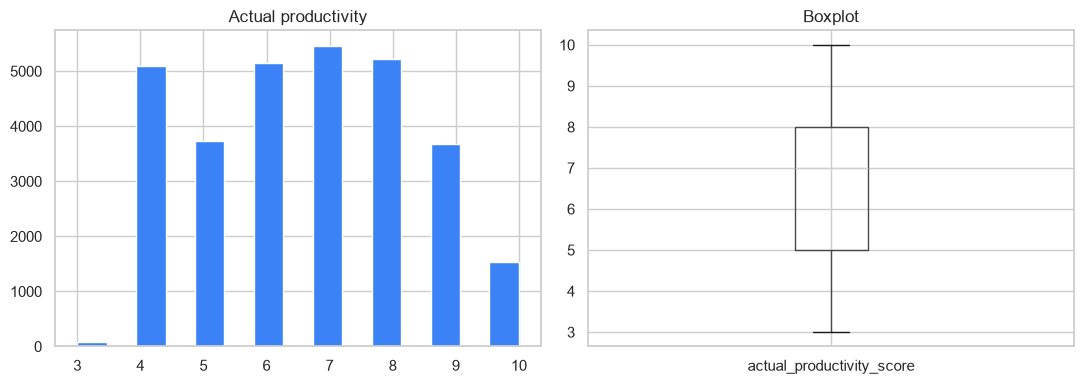

count   29961.00
mean        6.63
std         1.80
min         3.00
25%         5.00
50%         7.00
75%         8.00
max        10.00
Name: actual_productivity_score, dtype: float64


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df['actual_productivity_score'].hist(bins=15, ax=ax[0], color='#3b82f6', edgecolor='white')
ax[0].set_title('Actual productivity')
df.boxplot(column='actual_productivity_score', ax=ax[1])
ax[1].set_title('Boxplot')
plt.tight_layout()
plt.show()
print(df['actual_productivity_score'].describe())


## Cleaning rules

- Drop rows without target.
- Booleans to 0/1.
- Strip categorical strings.
- Missing categoricals filled with **Other** (option not listed on the form).


In [18]:
from src.preprocess import clean_frame, TARGET, ALL_FEATURES, NUMERIC_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES

clean = clean_frame(df)
print('Before:', df.shape, '-> After:', clean.shape)
print('\nCategorical after Other fill:')
for c in CATEGORICAL_FEATURES:
    print(c, clean[c].value_counts().to_dict())
print('\nRemaining missing (handled inside pipeline):')
print(clean.isna().sum()[clean.isna().sum() > 0])
clean.to_csv(ROOT / 'data' / 'cleaned.csv', index=False)
print('Saved data/cleaned.csv')


Before: (30000, 19) -> After: (29961, 19)

Categorical after Other fill:
gender {'Male': 14715, 'Female': 14097, 'Other': 1149}
job_type {'Student': 6545, 'IT': 5605, 'Health': 4986, 'Finance': 4355, 'Education': 4068, 'Unemployed': 3779, 'Other': 623}
social_platform_preference {'Instagram': 8431, 'TikTok': 7302, 'Facebook': 5279, 'Telegram': 4730, 'Twitter': 3607, 'Other': 612}

Remaining missing (handled inside pipeline):
daily_social_media_time    602
work_hours_per_day         576
sleep_hours                593
dtype: int64
Saved data/cleaned.csv


## Preprocessing pipeline

| Block | Steps |
|-------|-------|
| Numeric | median impute then StandardScaler |
| Boolean | most-frequent impute |
| Categorical | constant Other then OneHotEncoder |

Fit on train only, then transform test (no leakage).


In [19]:
from src.preprocess import build_preprocessor, split_xy
from sklearn.model_selection import train_test_split

X, y = split_xy(clean)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, 'Test:', X_test.shape)

pre = build_preprocessor()
X_train_t = pre.fit_transform(X_train)
X_test_t = pre.transform(X_test)
print('Transformed train:', X_train_t.shape)
print('Transformed test:', X_test_t.shape)


Train: (23968, 18) Test: (5993, 18)
Transformed train: (23968, 31)
Transformed test: (5993, 31)


## Feature names after one-hot + scaled numeric check


In [20]:
try:
    names = pre.get_feature_names_out()
    print(len(names), 'features')
    print(list(names)[:30])
except Exception as e:
    print(e)
print('\nNumeric means after scaling (should be near 0):')
print(np.asarray(X_train_t)[:, :len(NUMERIC_FEATURES)].mean(axis=0).round(4))


31 features
['num__age', 'num__daily_social_media_time', 'num__number_of_notifications', 'num__work_hours_per_day', 'num__perceived_productivity_score', 'num__stress_level', 'num__sleep_hours', 'num__screen_time_before_sleep', 'num__breaks_during_work', 'num__coffee_consumption_per_day', 'num__days_feeling_burnout_per_month', 'num__weekly_offline_hours', 'num__job_satisfaction_score', 'bool__uses_focus_apps', 'bool__has_digital_wellbeing_enabled', 'cat__gender_Female', 'cat__gender_Male', 'cat__gender_Other', 'cat__job_type_Education', 'cat__job_type_Finance', 'cat__job_type_Health', 'cat__job_type_IT', 'cat__job_type_Other', 'cat__job_type_Student', 'cat__job_type_Unemployed', 'cat__social_platform_preference_Facebook', 'cat__social_platform_preference_Instagram', 'cat__social_platform_preference_Other', 'cat__social_platform_preference_Telegram', 'cat__social_platform_preference_TikTok']

Numeric means after scaling (should be near 0):
[ 0. -0.  0.  0.  0.  0.  0.  0. -0.  0.  0. -0.

## Sklearn imputers in isolation

Numeric gaps use **median**. Categorical gaps use a constant value **Other** via `SimpleImputer` — not the most frequent label.


In [21]:
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd

# Categorical: blank form answers -> Other
cat_cols = ['job_type', 'social_platform_preference', 'gender']
before = clean[cat_cols].copy()
print('Missing before categorical imputer:')
print(before.isna().sum())

cat_imp = SimpleImputer(strategy='constant', fill_value='Other')
after_cat = pd.DataFrame(cat_imp.fit_transform(before), columns=cat_cols)
print('\nValue counts after constant Other imputer (job_type):')
print(after_cat['job_type'].value_counts())
print('\nValue counts after constant Other imputer (platform):')
print(after_cat['social_platform_preference'].value_counts())

# Numeric: median (only for continuous gaps)
num_cols = ['daily_social_media_time', 'work_hours_per_day', 'sleep_hours']
num_before = clean[num_cols]
print('\nNumeric missing before median imputer:')
print(num_before.isna().sum())
num_imp = SimpleImputer(strategy='median')
num_after = pd.DataFrame(num_imp.fit_transform(num_before), columns=num_cols)
print('Numeric missing after median imputer:', int(num_after.isna().sum().sum()))


Missing before categorical imputer:
job_type                      0
social_platform_preference    0
gender                        0
dtype: int64

Value counts after constant Other imputer (job_type):
job_type
Student       6545
IT            5605
Health        4986
Finance       4355
Education     4068
Unemployed    3779
Other          623
Name: count, dtype: int64

Value counts after constant Other imputer (platform):
social_platform_preference
Instagram    8431
TikTok       7302
Facebook     5279
Telegram     4730
Twitter      3607
Other         612
Name: count, dtype: int64

Numeric missing before median imputer:
daily_social_media_time    602
work_hours_per_day         576
sleep_hours                593
dtype: int64
Numeric missing after median imputer: 0
